     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 3.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Please upload your image:


Saving Object_detection.jpg to Object_detection.jpg

image 1/1 /content/Object_detection.jpg: 384x640 12 persons, 8 cars, 2 buss, 1 truck, 372.6ms
Speed: 23.1ms preprocess, 372.6ms inference, 36.1ms postprocess per image at shape (1, 3, 384, 640)


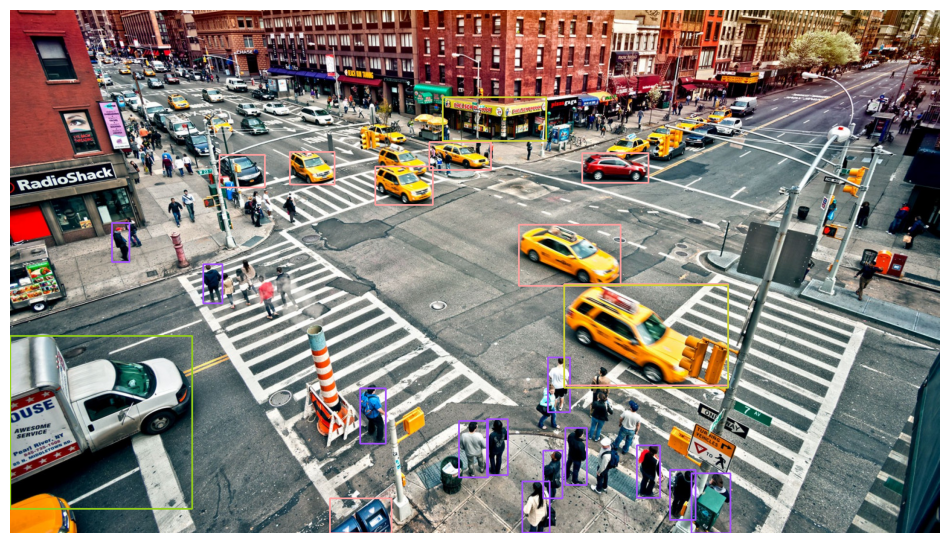

In [2]:
!pip install -q supervision ultralytics

import cv2
import os
import supervision as sv
import ultralytics
from ultralytics import YOLO
from google.colab import drive
from google.colab import files
import matplotlib.pyplot as plt

model = YOLO('yolov8n.pt')
print("Please upload your image:")
uploaded = files.upload()
if uploaded:
  Image_path = list(uploaded.keys())[0]
  results = model(Image_path)
  detections = sv.Detections.from_ultralytics(results[0])
  box_annotator = sv.BoxAnnotator()
  labels = [
      f"{model.model.names[class_id]} {confidence:0.2f}"
      for class_id, confidence in zip(detections.class_id, detections.confidence)
  ]

  detections.labels = labels

  image_to_annotate = cv2.imread(Image_path)

  annotated_image = box_annotator.annotate(
      scene = image_to_annotate,
      detections = detections
  )

  cv2.imwrite("annotated_image.jpg", annotated_image)

  %matplotlib inline
  sv.plot_image(annotated_image)